In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Del 1: Tid och dagar

## Vad vill vi ta reda på?
Seoul har ett system med hyrcyklar. Vi vill förutsäga hur många cyklar som hyrs ut varje timme.

I den här delen tittar vi bara på tiden, vilken timme det är, vilken veckodag, och om
folk är lediga.

**Datan:** en rad per timme under ett helt år (dec 2017 – nov 2018).
Källa: [UCI Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

In [8]:
df = pd.read_csv("../data/SeoulBikeData.csv", encoding="cp1252")
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Rensa bort data där systemet varit stängt.
stangda = (df["Functioning Day"] == "No").sum()
df = df[df["Functioning Day"] == "Yes"].copy()

TARGET = "Rented Bike Count"

print("Stängda timmar som tagits bort:", stangda)
print("Timmar kvar:", len(df))
print("Från", df["Date"].min().date(), "till", df["Date"].max().date())

Stängda timmar som tagits bort: 295
Timmar kvar: 8465
Från 2017-12-01 till 2018-11-30


Vi har **8465** timmar att arbeta med. 295 timmar togs bort eftersom systemet var stängt.

## Vilken sorts dag är det?
Datan har bara datum och en kolumn för helgdagar. Vi räknar själva fram veckodag och
om det är helg.

In [9]:
# 0-4 = vardag | 5-6 = helg
df["Veckodag"] = df["Date"].dt.day_of_week
df["Helg"] = df["Veckodag"] >= 5
df["Helgdag"] = df["Holiday"] == "Holiday"

Dagar totalt: 353
Helgdagar totalt: 17


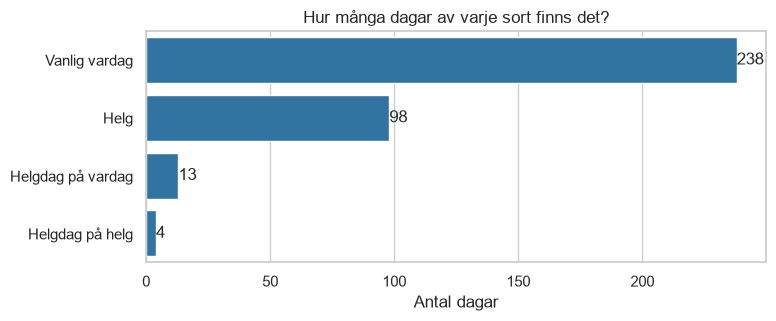

In [10]:
# En rad per dag
dagar = df.drop_duplicates("Date")

antal = pd.Series({
	"Vanlig vardag": (~dagar["Helg"] & ~dagar["Helgdag"]).sum(),
	"Helg": (dagar["Helg"] & ~dagar["Helgdag"]).sum(),
	"Helgdag på vardag": (dagar["Helgdag"] & ~dagar["Helg"]).sum(),
	"Helgdag på helg": (dagar["Helgdag"] & dagar["Helg"]).sum(),
})

print("Dagar totalt:", len(dagar))
print("Helgdagar totalt:", dagar["Helgdag"].sum())

plt.figure(figsize=(8, 3))
ax = sns.barplot(x=antal.values, y=antal.index, color="tab:blue")
ax.bar_label(ax.containers[0])
plt.title("Hur många dagar av varje sort finns det?")
plt.xlabel("Antal dagar")
plt.ylabel("")
plt.show()

Vi ser att av årets 353 dagar är bara 17 helgdagar, 13 infaller på en vardag och 4 på
en helg.

## Liknar helgdagar vardagar eller helger?

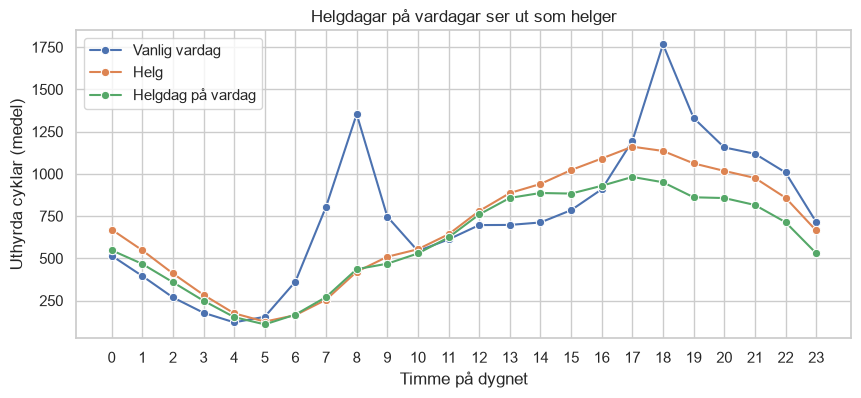

In [13]:
# Dela in tre sorters dagar
def dagtyp(rad):
	if rad["Helgdag"] and not rad["Helg"]:
		return "Helgdag på vardag"
	if rad["Helg"]:
		return "Helg"
	return "Vanlig vardag"

df["Dagtyp"] = df.apply(dagtyp, axis=1)

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x="Hour", y=TARGET, hue="Dagtyp", errorbar=None, marker="o",
	hue_order=["Vanlig vardag", "Helg", "Helgdag på vardag"])
plt.title("Helgdagar på vardagar ser ut som helger")
plt.xlabel("Timme på dygnet")
plt.ylabel("Uthyrda cyklar (medel)")
plt.xticks(range(24))
plt.legend(title="")
plt.show()

En helgdag på en vardag beter sig nästan exakt som en helg. Skillnaden är så liten att vi kan behandla dem som samma sak.

In [19]:
df["Ledig dag"] = df["Helg"] | df["Helgdag"]

print("Lediga dagar:", df[df["Ledig dag"]]["Date"].nunique())
print("Vanliga vardagar:", df[~df["Ledig dag"]]["Date"].nunique())

Lediga dagar: 115
Vanliga vardagar: 238


## Påverkar en ledig dag alla timmar lika mycket?

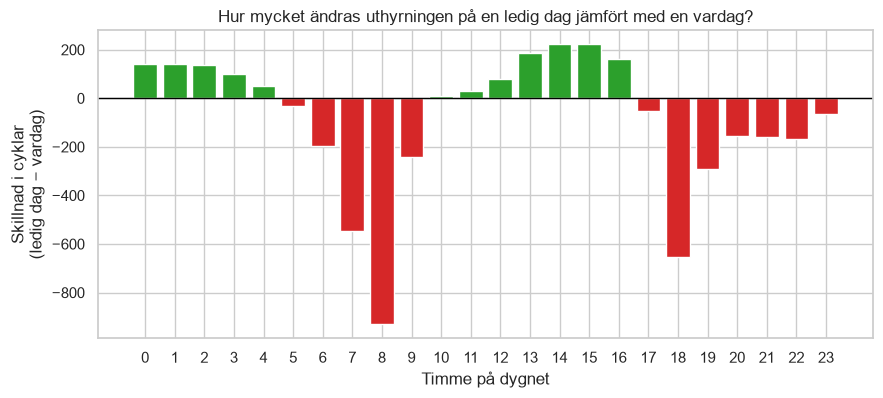

In [18]:
# Skillnaden mellan ledig dag och vardag (timme för timme)
jamfor = df.pivot_table(index="Hour", columns="Ledig dag", values=TARGET, aggfunc="mean")
skillnad = jamfor[True] - jamfor[False]

# Grönt = fler cyklar på ledig dag 
# Rött = färre
farger = ["tab:green" if v > 0 else "tab:red" for v in skillnad]

plt.figure(figsize=(10, 4))
plt.bar(skillnad.index, skillnad.values, color=farger)
plt.axhline(0, color="black", linewidth=1)
plt.title("Hur mycket ändras uthyrningen på en ledig dag jämfört med en vardag?")
plt.xlabel("Timme på dygnet")
plt.ylabel("Skillnad i cyklar\n(ledig dag − vardag)")
plt.xticks(range(24))
plt.show()

**En ledig dag** påverkar olika timmar på helt olika sätt. Det vi ser här är främst att rusningningstrafiken sticker ut och att fler cyklar på fritiden unde ren ledig dag.

## Referenspunkt: hur bra kan man gissa utan maskininlärning?
Om vi bara slår upp medelvärden i en tabell, hur fel blir vi i snitt?

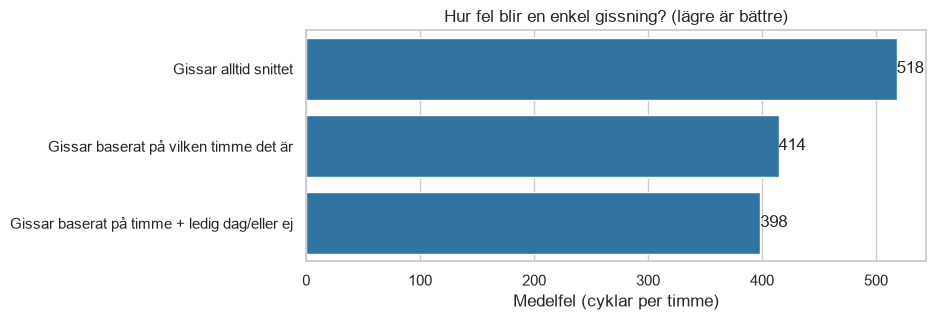

In [21]:
from sklearn.metrics import mean_absolute_error

# Tre allt smartare "mänskliga" gissningar
gissning_medel = pd.Series(df[TARGET].mean(), index=df.index)
gissning_timme = df.groupby("Hour")[TARGET].transform("mean")
gissning_ledig = df.groupby(["Hour", "Ledig dag"])[TARGET].transform("mean")

gissningar = pd.Series({
	"Gissar alltid snittet": mean_absolute_error(df[TARGET], gissning_medel),
	"Gissar baserat på vilken timme det är": mean_absolute_error(df[TARGET], gissning_timme),
	"Gissar baserat på timme + ledig dag/eller ej": mean_absolute_error(df[TARGET], gissning_ledig),
})

plt.figure(figsize=(8, 3))
ax = sns.barplot(x=gissningar.values, y=gissningar.index, color="tab:blue")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("Hur fel blir en enkel gissning? (lägre är bättre)")
plt.xlabel("Medelfel (cyklar per timme)")
plt.ylabel("")
plt.show()